# Projet – Étude de marché internationale
## La poule qui chante

### Notebook 2 – ACP, clustering et visualisations

**Objectif :** réduire la dimension des données préparées dans le Notebook 1, segmenter les pays avec K-Means, interpréter les groupes et identifier les marchés prioritaires.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Chargement du jeu de données préparé dans le Notebook 1
data_analyse = pd.read_csv("data_analyse_pret.csv", encoding="utf-8-sig")
print("Dimensions du jeu de données :", data_analyse.shape)

In [ ]:
# Sélection des variables quantitatives pour l'analyse multivariée

colonnes_identification = [
    "Code zone",
    "Zone",
    "Code_ISO3",
    "Code_pays"
]

variables_analyse = [
    col for col in data_analyse.columns
    if col not in colonnes_identification
]

X = data_analyse[variables_analyse].copy()

print("Colonnes d'identification :")
print(colonnes_identification)

print("\nVariables retenues pour l'analyse :")
for i, col in enumerate(variables_analyse, 1):
    print(f"{i}. {col}")

print("\nNombre de variables retenues :", len(variables_analyse))
print("Dimensions de X :", X.shape)

print("\nTypes présents dans X :")
print(X.dtypes.value_counts())

## 10.24 — Standardisation des variables quantitatives

Les variables retenues pour l'analyse présentent des unités et des ordres de grandeur très différents. Une standardisation est donc nécessaire avant de réaliser l'analyse en composantes principales (ACP).

La standardisation consiste à transformer chaque variable afin d'obtenir une **moyenne proche de 0** et un **écart-type proche de 1**. Cette transformation permet d'éviter que les variables ayant les valeurs numériques les plus élevées dominent artificiellement l'analyse.

La méthode utilisée est la standardisation **centrée-réduite**, réalisée avec `StandardScaler` de `scikit-learn`.

In [108]:
# Standardisation des 15 variables quantitatives

from sklearn.preprocessing import StandardScaler

# Création du standardiseur
scaler = StandardScaler()

# Standardisation des variables de X
X_standardise = scaler.fit_transform(X)

# Conversion en DataFrame pour conserver les noms des variables
X_standardise = pd.DataFrame(
    X_standardise,
    columns=X.columns,
    index=X.index
)

print("Dimensions avant standardisation :", X.shape)
print("Dimensions après standardisation :", X_standardise.shape)

display(X_standardise.head())

Dimensions avant standardisation : (161, 15)
Dimensions après standardisation : (161, 15)


,Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Production,Population,Taux_dependance_importations,Consommation_totale_tonnes,Solde_commercial,PIB_par_habitant,Croissance_PIB,Stabilite_politique,Taux_urbanisation,Utilisation_Internet,Emissions_CO2
0,-0.253589,-0.298367,-0.234996,-0.301503,-0.289188,-0.267095,0.571590,-0.291072,-0.111108,-0.539336,1.357302,-0.270893,0.249847,0.404246,-0.478318
1,-1.188928,-0.293897,-0.234996,-0.333000,-0.282508,-0.055316,0.115941,-0.287301,-0.098603,-0.709102,-0.296137,-3.012509,-1.611229,-1.476727,-0.814504
2,-0.234277,-0.298367,-0.234996,-0.285755,-0.288402,-0.267480,0.694875,-0.291122,-0.117361,-0.481591,-0.079390,0.280927,-0.157687,0.318176,-0.454441
3,-0.876719,-0.195545,-0.234996,-0.474736,-0.185449,-0.022975,-0.852788,-0.191874,-0.042331,-0.504525,-0.686927,-1.015379,0.558351,-0.221723,-0.046186
4,-0.607641,-0.176769,-0.234996,0.968873,-0.277007,-0.096460,0.810431,-0.168626,-0.615478,-0.591984,-1.254095,-0.550262,0.267235,-1.017908,-0.682664


In [109]:
# Vérification de la standardisation

controle_standardisation = pd.DataFrame({
    "Moyenne": X_standardise.mean(),
    "Ecart_type": X_standardise.std(ddof=0)
})

display(controle_standardisation.round(6))

print(
    "\nMoyenne absolue maximale :",
    X_standardise.mean().abs().max()
)

print(
    "Écart maximal par rapport à un écart-type de 1 :",
    (X_standardise.std(ddof=0) - 1).abs().max()
)

,Moyenne,Ecart_type
Disponibilité alimentaire en quantité (kg/personne/an),-0.0,1.0
Disponibilité intérieure,-0.0,1.0
Exportations - Quantité,-0.0,1.0
Importations - Quantité,-0.0,1.0
Production,0.0,1.0
Population,0.0,1.0
Taux_dependance_importations,0.0,1.0
Consommation_totale_tonnes,0.0,1.0
Solde_commercial,-0.0,1.0
PIB_par_habitant,0.0,1.0



Moyenne absolue maximale : 2.758318073602873e-16
Écart maximal par rapport à un écart-type de 1 : 1.5543122344752192e-15


### Conclusion de la standardisation

Les **15 variables quantitatives** ont été standardisées à l'aide de la méthode centrée-réduite (`StandardScaler`).

Les contrôles montrent qu'après transformation :

- chaque variable présente une **moyenne proche de 0** ;
- chaque variable présente un **écart-type proche de 1** ;
- les dimensions du jeu de données restent inchangées : **161 pays × 15 variables**.

La standardisation permet ainsi de rendre les variables comparables malgré leurs unités et leurs ordres de grandeur différents. Elle évite notamment que les variables présentant de grandes valeurs numériques, comme la population ou les volumes alimentaires, exercent une influence disproportionnée sur l'analyse.

Le jeu de données standardisé `X_standardise` est désormais prêt pour la réalisation de l'**analyse en composantes principales (ACP)**.

# 10.25 — Analyse en composantes principales (ACP)

Après la préparation, le contrôle et la standardisation des données, une **analyse en composantes principales (ACP)** est réalisée sur les **15 variables quantitatives standardisées**.

L'ACP permet de réduire la dimension du jeu de données en construisant de nouvelles variables, appelées **composantes principales**, qui résument une partie importante de l'information contenue dans les variables initiales.

Cette méthode permettra notamment :

- d'identifier les principaux axes de différenciation entre les pays ;
- de réduire la redondance liée aux fortes corrélations observées entre certaines variables ;
- d'évaluer la part de variance expliquée par chaque composante principale ;
- de déterminer le nombre de composantes à conserver ;
- de faciliter la représentation et l'interprétation du positionnement des pays.

L'ACP est réalisée à partir du jeu de données standardisé `X_standardise`, contenant **161 pays et 15 variables quantitatives**.

In [110]:
# Réalisation de l'Analyse en Composantes Principales (ACP)

from sklearn.decomposition import PCA

# Création de l'ACP sur l'ensemble des composantes
pca = PCA()

# Ajustement de l'ACP sur les données standardisées
X_pca = pca.fit_transform(X_standardise)

print("Dimensions avant ACP :", X_standardise.shape)
print("Dimensions après ACP :", X_pca.shape)
print("Nombre de composantes principales :", pca.n_components_)

Dimensions avant ACP : (161, 15)
Dimensions après ACP : (161, 15)
Nombre de composantes principales : 15


In [111]:
# Calcul de la variance expliquée par les composantes principales

import pandas as pd
import numpy as np

variance_expliquee = pca.explained_variance_ratio_
variance_cumulee = np.cumsum(variance_expliquee)

table_variance = pd.DataFrame({
    "Composante": [f"CP{i}" for i in range(1, len(variance_expliquee) + 1)],
    "Variance_expliquee_%": variance_expliquee * 100,
    "Variance_cumulee_%": variance_cumulee * 100
})

table_variance["Variance_expliquee_%"] = (
    table_variance["Variance_expliquee_%"].round(2)
)

table_variance["Variance_cumulee_%"] = (
    table_variance["Variance_cumulee_%"].round(2)
)

display(table_variance)

,Composante,Variance_expliquee_%,Variance_cumulee_%
0,CP1,33.46,33.46
1,CP2,24.57,58.03
2,CP3,9.36,67.40
3,CP4,7.66,75.06
4,CP5,6.58,81.64
5,CP6,4.63,86.27
6,CP7,3.88,90.15
7,CP8,2.91,93.07
8,CP9,2.59,95.65
9,CP10,1.95,97.60


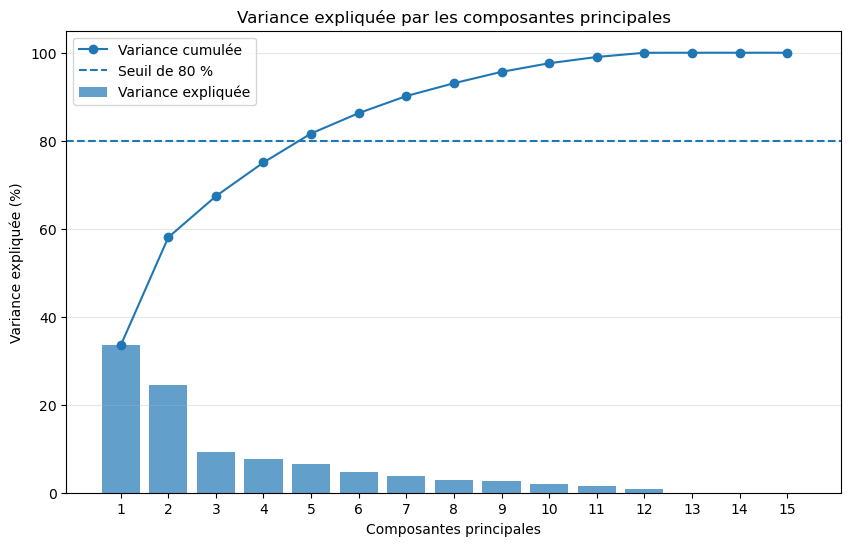

In [112]:
# Visualisation de la variance expliquée par l'ACP

import matplotlib.pyplot as plt

composantes = np.arange(1, len(variance_expliquee) + 1)

plt.figure(figsize=(10, 6))

plt.bar(
    composantes,
    variance_expliquee * 100,
    alpha=0.7,
    label="Variance expliquée"
)

plt.plot(
    composantes,
    variance_cumulee * 100,
    marker="o",
    label="Variance cumulée"
)

# Seuil de 80 %
plt.axhline(
    y=80,
    linestyle="--",
    label="Seuil de 80 %"
)

plt.xlabel("Composantes principales")
plt.ylabel("Variance expliquée (%)")
plt.title("Variance expliquée par les composantes principales")

plt.xticks(composantes)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

### Choix du nombre de composantes principales

L'analyse de la variance expliquée montre que les premières composantes concentrent une part importante de l'information contenue dans les données.

Les deux premières composantes expliquent à elles seules **58,03 % de la variance totale**. La variance cumulée atteint ensuite :

- **67,40 %** avec 3 composantes ;
- **75,06 %** avec 4 composantes ;
- **81,64 %** avec 5 composantes ;
- **90,15 %** avec 7 composantes.

Un seuil de **80 % de variance expliquée cumulée** est retenu afin d'obtenir un compromis entre réduction de dimension et conservation de l'information.

Le seuil de 80 % étant dépassé avec **5 composantes principales**, les **5 premières composantes (CP1 à CP5)** sont retenues pour la suite de l'analyse.

L'ACP permet ainsi de passer de **15 variables quantitatives initiales à 5 composantes principales**, tout en conservant **81,64 % de l'information totale**.

**Décision : 5 composantes principales sont retenues pour la suite de l'analyse.**

In [113]:
# Construction de l'ACP réduite aux 5 composantes retenues

pca_5 = PCA(n_components=5)

# Projection des données standardisées sur les 5 composantes
X_pca_5 = pca_5.fit_transform(X_standardise)

# Création d'un DataFrame pour faciliter les analyses suivantes
df_pca = pd.DataFrame(
    X_pca_5,
    columns=["CP1", "CP2", "CP3", "CP4", "CP5"],
    index=X_standardise.index
)

print("Dimensions des données initiales standardisées :", X_standardise.shape)
print("Dimensions après réduction par ACP :", df_pca.shape)
print(
    "Variance totale conservée :",
    round(pca_5.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

display(df_pca.head())

Dimensions des données initiales standardisées : (161, 15)
Dimensions après réduction par ACP : (161, 5)
Variance totale conservée : 81.64 %


,CP1,CP2,CP3,CP4,CP5
0,-0.806616,-0.038615,-0.187123,0.605563,0.924326
1,-2.213352,-2.592013,0.370078,-1.271407,-0.436783
2,-0.754423,0.264831,-0.260542,-0.313104,0.488779
3,-0.701184,-0.620611,0.074640,-0.162061,-1.198613
4,-0.990064,-0.217403,1.048144,-1.838655,0.130797


In [114]:
# Poids des variables initiales dans les 5 composantes principales

loadings = pd.DataFrame(
    pca_5.components_.T,
    index=X_standardise.columns,
    columns=["CP1", "CP2", "CP3", "CP4", "CP5"]
)

# Affichage arrondi pour faciliter l'interprétation
display(loadings.round(3))

,CP1,CP2,CP3,CP4,CP5
Disponibilité alimentaire en quantité (kg/personne/an),0.223,0.250,-0.154,-0.064,-0.248
Disponibilité intérieure,0.381,-0.237,0.146,0.009,0.005
Exportations - Quantité,0.350,-0.145,-0.327,-0.208,0.152
Importations - Quantité,0.162,0.147,0.557,-0.274,0.170
Production,0.389,-0.244,0.029,-0.010,0.020
Population,0.202,-0.255,0.428,0.195,0.042
Taux_dependance_importations,-0.023,0.202,0.034,-0.494,0.680
Consommation_totale_tonnes,0.383,-0.235,0.132,-0.001,0.009
Solde_commercial,0.279,-0.201,-0.542,-0.096,0.082
PIB_par_habitant,0.217,0.331,-0.035,0.231,0.144


In [115]:
# Identification des variables les plus importantes pour chaque composante

for cp in loadings.columns:
    
    principales_variables = (
        loadings[cp]
        .sort_values(key=abs, ascending=False)
        .head(5)
    )
    
    print(f"\n--- {cp} ---")
    
    for variable, poids in principales_variables.items():
        print(f"{variable} : {poids:.3f}")


--- CP1 ---
Production : 0.389
Consommation_totale_tonnes : 0.383
Disponibilité intérieure : 0.381
Exportations - Quantité : 0.350
Solde_commercial : 0.279

--- CP2 ---
Utilisation_Internet : 0.378
Stabilite_politique : 0.350
PIB_par_habitant : 0.331
Taux_urbanisation : 0.312
Emissions_CO2 : 0.289

--- CP3 ---
Importations - Quantité : 0.557
Solde_commercial : -0.542
Population : 0.428
Exportations - Quantité : -0.327
Disponibilité alimentaire en quantité (kg/personne/an) : -0.154

--- CP4 ---
Croissance_PIB : 0.666
Taux_dependance_importations : -0.494
Importations - Quantité : -0.274
PIB_par_habitant : 0.231
Stabilite_politique : 0.226

--- CP5 ---
Taux_dependance_importations : 0.680
Croissance_PIB : 0.493
Stabilite_politique : 0.284
Emissions_CO2 : -0.249
Disponibilité alimentaire en quantité (kg/personne/an) : -0.248


### Interprétation des composantes principales

L'examen des poids des variables permet de donner une interprétation synthétique aux cinq composantes retenues.

- **CP1 — Volume et puissance du système alimentaire :** cet axe est principalement associé à la production, à la consommation totale, à la disponibilité intérieure et aux exportations. Il distingue notamment les pays selon l'importance de leurs volumes alimentaires et commerciaux.

- **CP2 — Développement socio-économique et infrastructurel :** cet axe est principalement associé à l'utilisation d'Internet, à la stabilité politique, au PIB par habitant, au taux d'urbanisation et aux émissions de CO₂. Il traduit globalement un niveau de développement économique, institutionnel et infrastructurel.

- **CP3 — Orientation commerciale et dépendance aux importations :** les importations et la population contribuent positivement à cet axe, tandis que le solde commercial et les exportations y contribuent négativement. Cet axe permet ainsi de différencier les pays selon la structure de leurs échanges alimentaires.

- **CP4 — Dynamique économique et autonomie extérieure :** cet axe est fortement associé à la croissance du PIB et s'oppose notamment au taux de dépendance aux importations. Il met en évidence des différences de dynamique économique et de dépendance extérieure.

- **CP5 — Dépendance extérieure et dynamique économique :** cet axe est principalement porté par le taux de dépendance aux importations et la croissance du PIB, avec une opposition aux émissions de CO₂ et à la disponibilité alimentaire par habitant. Son interprétation est plus spécifique et complète les dimensions mises en évidence par les premiers axes.

Ces composantes synthétisent différentes dimensions économiques, alimentaires, commerciales, institutionnelles, technologiques et environnementales du jeu de données. Elles serviront à analyser le positionnement relatif des pays dans un espace de dimension réduite.

### 10.25.6 — Projection des pays sur le premier plan factoriel (CP1–CP2)

Les deux premières composantes principales expliquent 58,03 % de la variance totale.  
La projection des pays sur le plan factoriel CP1–CP2 permet de visualiser leur positionnement selon les deux principales dimensions mises en évidence par l'ACP.

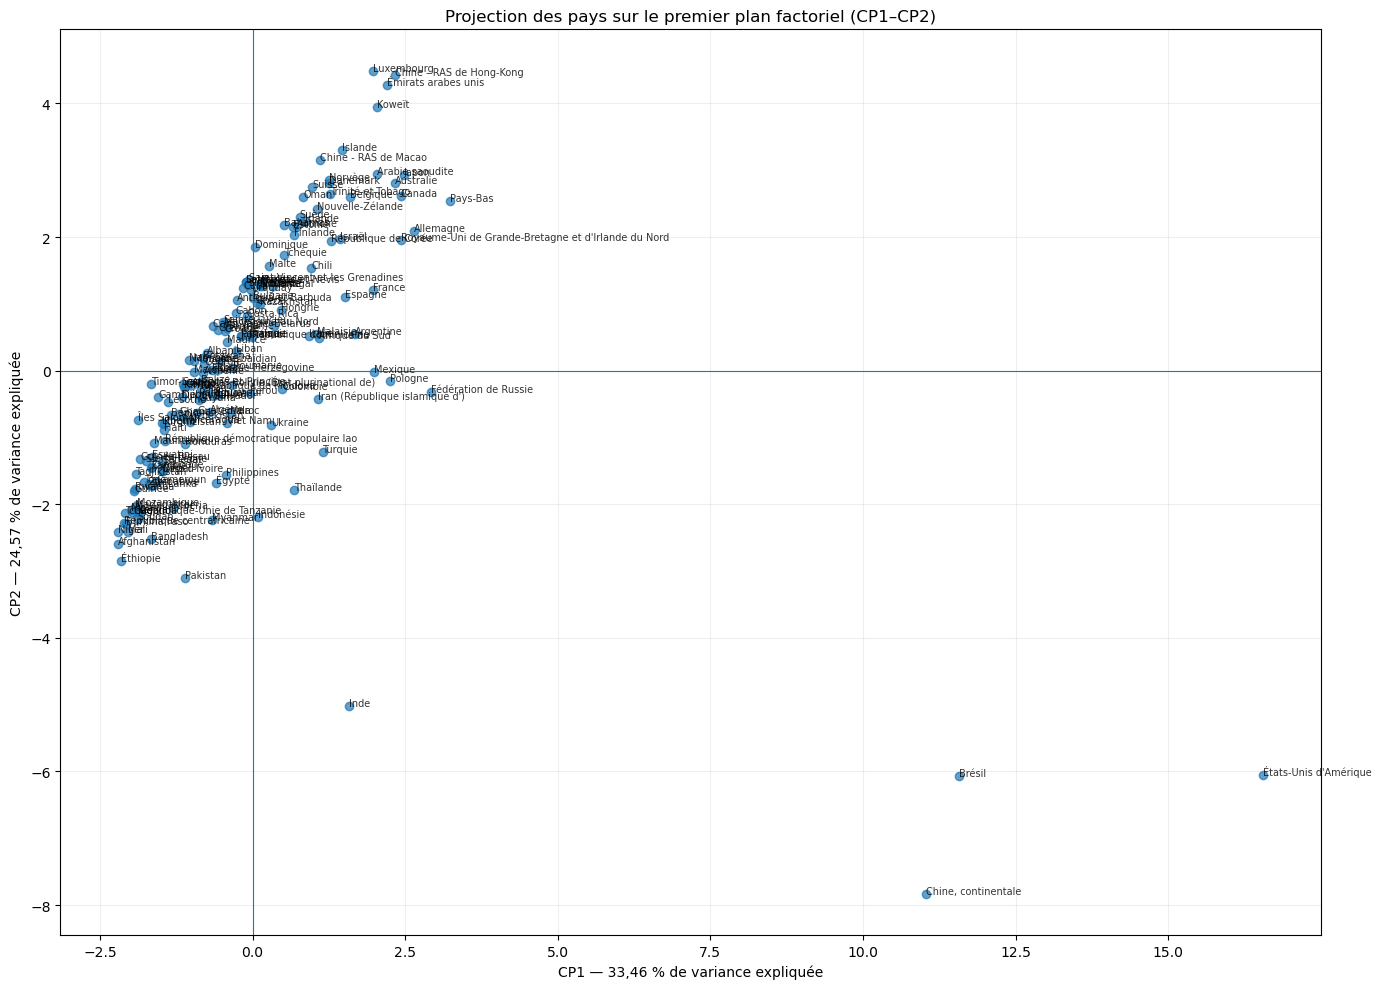

In [116]:
# Projection des pays sur le premier plan factoriel CP1-CP2

import matplotlib.pyplot as plt

# Récupération des noms des pays
pays = data_analyse["Zone"].reset_index(drop=True)

# Création du graphique
plt.figure(figsize=(14, 10))

plt.scatter(
    X_pca[:, 0],   # CP1
    X_pca[:, 1],   # CP2
    alpha=0.7
)

# Ajout du nom de chaque pays
for i, pays_nom in enumerate(pays):
    plt.annotate(
        pays_nom,
        (X_pca[i, 0], X_pca[i, 1]),
        fontsize=7,
        alpha=0.8
    )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("CP1 — 33,46 % de variance expliquée")
plt.ylabel("CP2 — 24,57 % de variance expliquée")
plt.title("Projection des pays sur le premier plan factoriel (CP1–CP2)")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Interprétation du premier plan factoriel

Le premier plan factoriel, constitué de CP1 et CP2, représente **58,03 % de la variance totale** du jeu de données.

La majorité des pays se concentre autour de l'origine, ce qui traduit des profils relativement proches sur les deux premières dimensions de l'ACP.

Certains pays se distinguent cependant nettement. Les **États-Unis** et le **Brésil** présentent notamment des positions très éloignées sur CP1, axe principalement associé aux volumes de production, de consommation et de disponibilité alimentaire. **L'Inde** présente également un positionnement particulier.

CP2 permet davantage de différencier les pays selon leur niveau de développement socio-économique et infrastructurel, notamment à travers l'utilisation d'Internet, la stabilité politique, le PIB par habitant et le taux d'urbanisation.

Cette représentation confirme l'existence de profils de pays différents et constitue une première étape avant leur regroupement par des méthodes de classification.

### 10.25.7 — Visualisation des pays les plus caractéristiques sur le plan CP1–CP2

Afin d'améliorer la lisibilité du premier plan factoriel, tous les pays sont représentés, mais seuls les pays les plus éloignés de l'origine sont identifiés par leur nom.

Ces pays présentent les profils les plus différenciés sur les deux premières composantes principales.

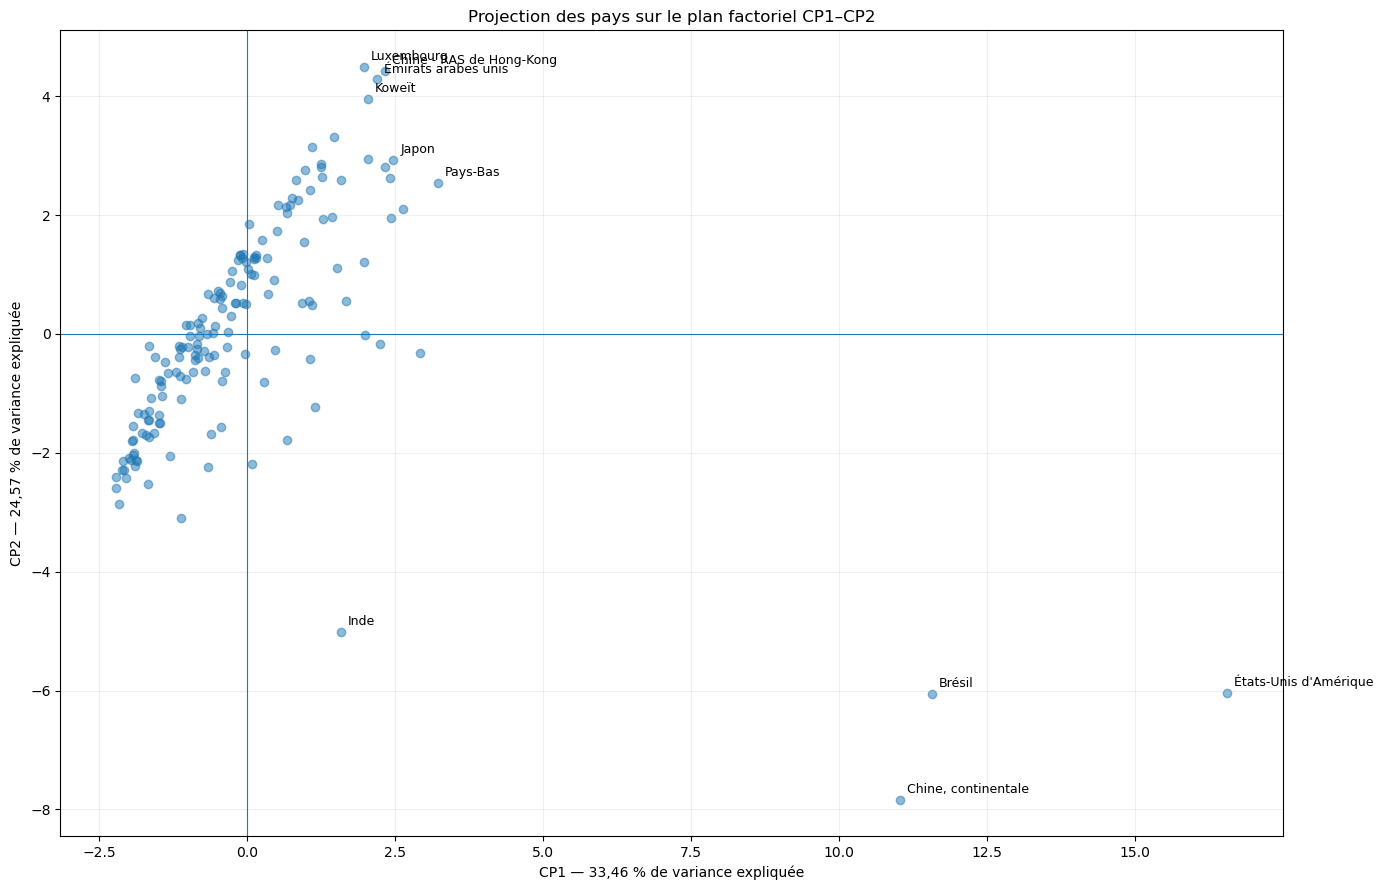

In [117]:
# Visualisation améliorée du premier plan factoriel CP1-CP2

import numpy as np
import matplotlib.pyplot as plt

# Coordonnées des pays sur CP1 et CP2
coord_cp1 = X_pca[:, 0]
coord_cp2 = X_pca[:, 1]

# Distance de chaque pays à l'origine du plan factoriel
distances = np.sqrt(coord_cp1**2 + coord_cp2**2)

# Sélection des 10 pays les plus éloignés de l'origine
indices_remarquables = np.argsort(distances)[-10:]

# Création du graphique
plt.figure(figsize=(14, 9))

# Tous les pays
plt.scatter(
    coord_cp1,
    coord_cp2,
    alpha=0.5
)

# Noms des 10 pays les plus caractéristiques
for i in indices_remarquables:
    plt.annotate(
        pays.iloc[i],
        (coord_cp1[i], coord_cp2[i]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

# Axes
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("CP1 — 33,46 % de variance expliquée")
plt.ylabel("CP2 — 24,57 % de variance expliquée")
plt.title("Projection des pays sur le plan factoriel CP1–CP2")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Conclusion de l'Analyse en Composantes Principales

L'Analyse en Composantes Principales a permis de synthétiser les **15 variables quantitatives initiales** en un nombre réduit de dimensions tout en conservant une part importante de l'information.

Les **5 premières composantes principales** ont été retenues car elles expliquent **81,64 % de la variance totale**. Cette réduction permet ainsi de passer de **15 variables à 5 composantes**, en limitant la perte d'information.

L'interprétation des composantes met en évidence plusieurs dimensions structurantes pour l'étude des marchés :

- **CP1** traduit principalement le volume et la puissance du système alimentaire ;
- **CP2** reflète davantage le développement socio-économique et infrastructurel ;
- **CP3** caractérise la structure des échanges commerciaux et l'orientation vers les importations ;
- **CP4** traduit principalement la dynamique économique et l'autonomie extérieure ;
- **CP5** complète l'analyse de la dépendance extérieure et de la dynamique économique.

Le premier plan factoriel **CP1–CP2 explique 58,03 % de la variance totale** et met en évidence des différences importantes entre les profils des pays. Certains pays, notamment les États-Unis, le Brésil et l'Inde, présentent des positionnements particulièrement éloignés de la majorité des observations.

L'ACP permet donc de réduire la redondance entre les indicateurs et de disposer d'une représentation synthétique des caractéristiques des pays.

Les **5 composantes principales retenues serviront désormais de base à la classification des pays**, afin d'identifier des groupes présentant des profils similaires et, à terme, les marchés les plus pertinents pour le développement international de l'entreprise.

## 10.26 — Classification des pays

Après la réduction dimensionnelle réalisée par l'Analyse en Composantes Principales (ACP), une classification des pays est réalisée à partir des **5 composantes principales retenues**, représentant **81,64 % de la variance totale**.

L'objectif est de regrouper les **161 pays** en ensembles homogènes présentant des caractéristiques économiques, alimentaires, commerciales et socio-environnementales similaires.

La classification permettra notamment :

- d'identifier différents profils de marchés ;
- de comparer les caractéristiques des groupes de pays ;
- de faciliter l'identification des marchés présentant un potentiel intéressant pour le développement international de l'entreprise.

La première étape consiste à déterminer un **nombre pertinent de groupes (clusters)** avant de réaliser la classification.

### 10.26.1 — Détermination du nombre de clusters : méthode du coude

Avant d'appliquer l'algorithme K-Means, il est nécessaire de déterminer un nombre pertinent de groupes.

La méthode du coude consiste à calculer l'inertie pour différents nombres de clusters. L'objectif est d'identifier le point à partir duquel l'ajout de nouveaux clusters n'améliore plus fortement la qualité de la partition.

  File "C:\Users\agner\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\agner\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\agner\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\agner\anaconda3\Lib\subprocess.

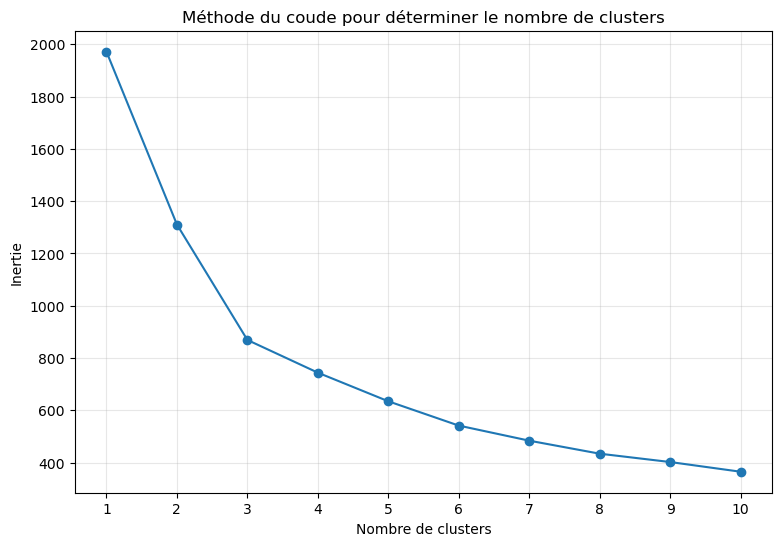

In [118]:
# Détermination du nombre de clusters par la méthode du coude

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Données utilisées : les 5 composantes principales retenues
X_classification = X_pca[:, :5]

# Test de 1 à 10 clusters
k_values = range(1, 11)
inerties = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_classification)
    inerties.append(kmeans.inertia_)

# Représentation graphique
plt.figure(figsize=(9, 6))
plt.plot(k_values, inerties, marker="o")

plt.xlabel("Nombre de clusters")
plt.ylabel("Inertie")
plt.title("Méthode du coude pour déterminer le nombre de clusters")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.show()

In [119]:
 # Validation du nombre de clusters avec le score de silhouette

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

scores_silhouette = []

for k in range(2, 8):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(X_classification)
    score = silhouette_score(X_classification, labels)
    scores_silhouette.append(score)

    print(f"{k} clusters : score de silhouette = {score:.3f}")

2 clusters : score de silhouette = 0.780
3 clusters : score de silhouette = 0.332
4 clusters : score de silhouette = 0.255
5 clusters : score de silhouette = 0.256
6 clusters : score de silhouette = 0.256
7 clusters : score de silhouette = 0.257


In [120]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "1"

## 10.26.2 — Choix final du nombre de clusters

Les deux méthodes ne conduisent pas exactement à la même indication. La méthode du coude suggère environ **3 clusters**, tandis que le score de silhouette atteint sa meilleure valeur avec **2 clusters (0,780)**.

Cependant, la classification avec 2 clusters conduit à une répartition très déséquilibrée : **158 pays dans un premier groupe contre seulement 3 pays dans le second**. Ces trois pays sont le **Brésil, la Chine continentale et les États-Unis**, qui présentent des volumes alimentaires et démographiques particulièrement élevés.

La classification avec **3 clusters** fournit une segmentation plus interprétable :

- **Cluster 0 : 85 pays** ;
- **Cluster 1 : 73 pays** ;
- **Cluster 2 : 3 pays**.

Cette solution permet de distinguer deux grands profils de marchés tout en isolant les trois pays présentant des caractéristiques particulièrement atypiques.

**Décision : 3 clusters sont retenus pour la classification finale, car cette solution offre un meilleur compromis entre les critères statistiques et l'interprétation métier.**


In [121]:
# Test de la classification des pays avec K-Means - 2 clusters

from sklearn.cluster import KMeans
import pandas as pd

# Modèle K-Means de test avec 2 clusters
kmeans_final = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Attribution d'un cluster à chaque pays
clusters = kmeans_final.fit_predict(X_classification)

# Création d'un tableau avec les pays et leur cluster
resultats_clusters = pd.DataFrame({
    "Pays": pays,
    "Cluster": clusters
})

# Nombre de pays dans chaque cluster
print("Répartition des pays par cluster :")
print(resultats_clusters["Cluster"].value_counts().sort_index())

# Aperçu des résultats
display(resultats_clusters.head(10))

Répartition des pays par cluster :
Cluster
0      3
1    158
Name: count, dtype: int64


,Pays,Cluster
0,Arménie,1
1,Afghanistan,1
2,Albanie,1
3,Algérie,1
4,Angola,1
5,Antigua-et-Barbuda,1
6,Argentine,1
7,Australie,1
8,Autriche,1
9,Bahamas,1


In [122]:
# Identifier les pays du petit cluster

resultats_clusters[
    resultats_clusters["Cluster"] == 0
]

,Pays,Cluster
14,Brésil,0
26,"Chine, continentale",0
151,États-Unis d'Amérique,0


In [123]:
# Test de la classification avec 3 clusters

kmeans_3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters_3 = kmeans_3.fit_predict(X_classification)

resultats_clusters_3 = pd.DataFrame({
    "Pays": pays,
    "Cluster": clusters_3
})

print("Répartition des pays avec 3 clusters :")
print(resultats_clusters_3["Cluster"].value_counts().sort_index())

Répartition des pays avec 3 clusters :
Cluster
0    85
1    73
2     3
Name: count, dtype: int64


In [124]:
# Aperçu des pays appartenant aux 3 clusters

for cluster in sorted(resultats_clusters_3["Cluster"].unique()):
    liste_pays = resultats_clusters_3[
        resultats_clusters_3["Cluster"] == cluster
    ]["Pays"].tolist()

    print(f"\n--- CLUSTER {cluster} : {len(liste_pays)} pays ---")
    print(liste_pays[:20])


--- CLUSTER 0 : 85 pays ---
['Arménie', 'Afghanistan', 'Albanie', 'Algérie', 'Angola', 'Bangladesh', 'Bolivie (État plurinational de)', 'Botswana', 'Belize', 'Îles Salomon', 'Myanmar', 'Cameroun', 'Cabo Verde', 'République centrafricaine', 'Sri Lanka', 'Tchad', 'Congo', 'Azerbaïdjan', 'Bénin', 'Équateur']

--- CLUSTER 1 : 73 pays ---
['Antigua-et-Barbuda', 'Argentine', 'Australie', 'Autriche', 'Bahamas', 'Barbade', 'Bulgarie', 'Canada', 'Chili', 'Colombie', 'Costa Rica', 'Cuba', 'Chypre', 'Danemark', 'Dominique', 'République dominicaine', 'Bélarus', 'Estonie', 'Finlande', 'France']

--- CLUSTER 2 : 3 pays ---
['Brésil', 'Chine, continentale', "États-Unis d'Amérique"]


In [125]:
# Caractérisation des 3 clusters avec les variables quantitatives originales

# Copie des données quantitatives avant standardisation
profils_clusters = X.copy()

# Ajout du numéro de cluster
profils_clusters["Cluster"] = clusters_3

# Moyenne de chaque variable par cluster
moyennes_clusters = profils_clusters.groupby("Cluster").mean()

# Affichage
display(moyennes_clusters.round(2))

,Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Production,Population,Taux_dependance_importations,Consommation_totale_tonnes,Solde_commercial,PIB_par_habitant,Croissance_PIB,Stabilite_politique,Taux_urbanisation,Utilisation_Internet,Emissions_CO2
Cluster,,,,,,,,,,,,,,,
0,9.98,299.76,19.15,35.08,287.47,4.511252e+07,39.31,270382.47,-15.93,2861.12,4.19,-0.55,46.68,33.25,1.47
1,30.89,590.84,105.63,155.10,568.10,1.996831e+07,53.15,567572.82,-49.47,27545.46,2.73,0.49,73.46,76.92,7.23
2,38.68,15469.67,2830.33,192.67,18117.00,6.513135e+08,1.06,15201392.14,2637.67,26369.30,3.56,-0.23,75.61,69.68,8.49


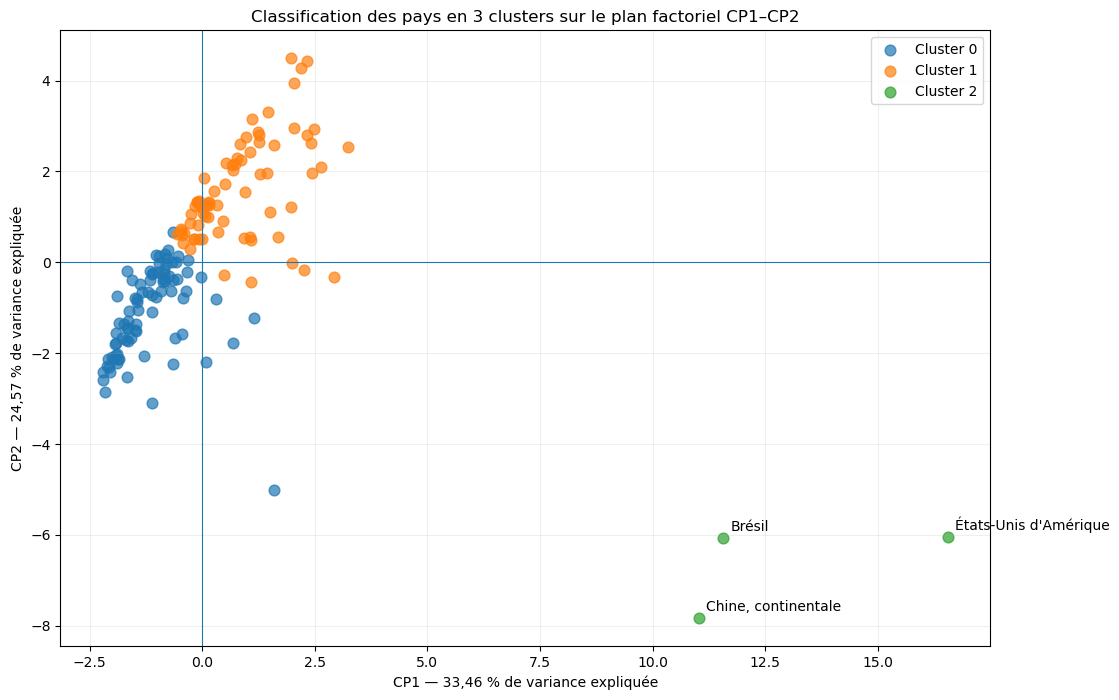

In [126]:
# Visualisation des 3 clusters sur le premier plan factoriel CP1-CP2

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

# Affichage des trois clusters
for cluster in sorted(set(clusters_3)):
    masque = clusters_3 == cluster

    plt.scatter(
        X_pca[masque, 0],
        X_pca[masque, 1],
        label=f"Cluster {cluster}",
        alpha=0.7,
        s=60
    )

# Mise en évidence des 3 pays atypiques
for i, nom_pays in enumerate(pays):
    if clusters_3[i] == 2:
        plt.annotate(
            nom_pays,
            (X_pca[i, 0], X_pca[i, 1]),
            xytext=(5, 5),
            textcoords="offset points"
        )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("CP1 — 33,46 % de variance expliquée")
plt.ylabel("CP2 — 24,57 % de variance expliquée")
plt.title("Classification des pays en 3 clusters sur le plan factoriel CP1–CP2")

plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 10.26.3 — Interprétation de la classification des pays

La classification K-Means réalisée à partir des **5 composantes principales** conduit à une segmentation finale en **3 clusters**.

Le **cluster 0**, composé de **85 pays**, regroupe globalement des pays caractérisés par des niveaux plus faibles de développement économique et infrastructurel. Il présente notamment un PIB par habitant, un taux d'urbanisation et une utilisation d'Internet plus faibles en moyenne.

Le **cluster 1**, composé de **73 pays**, rassemble globalement des pays présentant des indicateurs socio-économiques plus favorables. Il se caractérise notamment par un PIB par habitant plus élevé, une urbanisation plus importante, une utilisation d'Internet plus développée et une meilleure stabilité politique moyenne. Ce groupe constitue donc un ensemble de marchés potentiellement intéressants à approfondir pour le développement international de l'entreprise.

Le **cluster 2**, composé uniquement du **Brésil, de la Chine continentale et des États-Unis**, se distingue très fortement des autres groupes par l'importance de ses volumes de production, de consommation et de disponibilité alimentaire ainsi que par sa population. Ces pays constituent des marchés de très grande dimension et doivent être analysés séparément.

La projection sur le premier plan factoriel **CP1–CP2**, qui représente **58,03 % de la variance totale**, permet de visualiser cette différenciation entre les profils de pays.

**Conclusion : la classification en 3 clusters fournit une segmentation interprétable des marchés et constitue une base pour identifier les pays les plus intéressants pour le développement international de l'entreprise.**

In [127]:
# Sélection des pays candidats du cluster 1

pays_cluster1 = resultats_clusters_3[
    resultats_clusters_3["Cluster"] == 1
].copy()

print("Nombre de pays candidats :", len(pays_cluster1))

display(pays_cluster1.head(20))

Nombre de pays candidats : 73


,Pays,Cluster
5,Antigua-et-Barbuda,1
6,Argentine,1
7,Australie,1
8,Autriche,1
9,Bahamas,1
10,Barbade,1
17,Bulgarie,1
20,Canada,1
25,Chili,1
27,Colombie,1


In [128]:
# Construction du tableau des pays candidats avec leurs indicateurs

# Masque correspondant au cluster 1
masque_cluster1 = clusters_3 == 1

# Sélection des données quantitatives correspondantes
candidats = X.iloc[masque_cluster1].copy()

# Réinitialisation de l'index
candidats = candidats.reset_index(drop=True)

# Ajout du nom des pays
candidats.insert(
    0,
    "Pays",
    resultats_clusters_3.loc[
        resultats_clusters_3["Cluster"] == 1,
        "Pays"
    ].values
)

print("Dimensions du tableau des candidats :", candidats.shape)

display(candidats.head(10))

Dimensions du tableau des candidats : (73, 16)


,Pays,Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Production,Population,Taux_dependance_importations,Consommation_totale_tonnes,Solde_commercial,PIB_par_habitant,Croissance_PIB,Stabilite_politique,Taux_urbanisation,Utilisation_Internet,Emissions_CO2
0,Antigua-et-Barbuda,54.10,7.0,0.0,7.0,0.0,95426.0,100.000000,5.162547e+03,-7.0,16965.728827,2.712727,0.614623,24.850026,70.544197,3.064067
1,Argentine,42.24,1962.0,207.0,8.0,2161.0,43937140.0,0.407747,1.855905e+06,199.0,14532.500931,2.818503,0.239407,91.677603,74.294907,4.321029
2,Australie,47.65,1171.0,42.0,16.0,1269.0,24584620.0,1.366354,1.171457e+06,26.0,54117.547719,2.293310,0.783148,87.128093,86.545049,16.720945
3,Autriche,18.20,173.0,78.0,110.0,148.0,8819901.0,63.583815,1.605222e+05,-32.0,47163.742578,2.272250,0.926696,67.905120,87.935587,7.966419
4,Bahamas,43.17,26.0,0.0,24.0,6.0,381755.0,92.307692,1.648036e+04,-24.0,31875.488175,3.371399,0.818667,82.081402,80.599998,3.518189
5,Barbade,46.78,17.0,0.0,2.0,15.0,286232.0,11.764706,1.338993e+04,-2.0,20870.759643,0.654656,0.839990,59.259270,71.148499,2.433871
6,Bulgarie,22.06,157.0,45.0,108.0,107.0,7102444.0,68.789809,1.566799e+05,-63.0,8697.133733,2.745927,0.406139,73.390457,63.410101,7.243835
7,Canada,39.02,1433.0,163.0,182.0,1417.0,36732095.0,12.700628,1.433286e+06,-19.0,45129.733528,3.033835,1.019214,81.401895,92.701401,16.196245
8,Chili,36.36,672.0,115.0,155.0,712.0,18470439.0,23.065476,6.715852e+05,-40.0,14879.908623,1.357695,0.589419,87.800030,82.327487,4.836098
9,Colombie,31.99,1643.0,2.0,78.0,1564.0,48909839.0,4.747413,1.564626e+06,-76.0,6479.532313,1.359361,-0.779948,77.224519,62.259880,1.682892


In [129]:
# Sélection des critères pour évaluer l'attractivité des marchés

criteres_attractivite = [
    "Disponibilité alimentaire en quantité (kg/personne/an)",
    "Importations - Quantité",
    "Taux_dependance_importations",
    "PIB_par_habitant",
    "Croissance_PIB",
    "Stabilite_politique",
    "Taux_urbanisation",
    "Utilisation_Internet"
]

# Vérification des critères disponibles
print("Critères retenus pour l'analyse des marchés :")
for critere in criteres_attractivite:
    print("-", critere)

Critères retenus pour l'analyse des marchés :
- Disponibilité alimentaire en quantité (kg/personne/an)
- Importations - Quantité
- Taux_dependance_importations
- PIB_par_habitant
- Croissance_PIB
- Stabilite_politique
- Taux_urbanisation
- Utilisation_Internet


In [130]:
# Standardisation des critères d'attractivité

from sklearn.preprocessing import StandardScaler

# Copie du tableau des pays candidats
candidats_score = candidats.copy()

# Standardisation des 8 critères retenus
scaler_attractivite = StandardScaler()

criteres_standardises = scaler_attractivite.fit_transform(
    candidats_score[criteres_attractivite]
)

# Création d'un DataFrame avec les valeurs standardisées
df_criteres_std = pd.DataFrame(
    criteres_standardises,
    columns=criteres_attractivite,
    index=candidats_score.index
)

print("Dimensions après standardisation :", df_criteres_std.shape)

display(df_criteres_std.head())

Dimensions après standardisation : (73, 8)


,Disponibilité alimentaire en quantité (kg/personne/an),Importations - Quantité,Taux_dependance_importations,PIB_par_habitant,Croissance_PIB,Stabilite_politique,Taux_urbanisation,Utilisation_Internet
0,1.724170,-0.586405,0.870499,-0.476870,-0.006056,0.199189,-2.859890,-0.487120
1,0.842981,-0.582445,-0.980137,-0.586545,0.031640,-0.422579,1.071972,-0.200643
2,1.244940,-0.550768,-0.962324,1.197708,-0.155526,0.478450,0.804298,0.735016
3,-0.943173,-0.178563,0.193809,0.884272,-0.163031,0.716321,-0.326704,0.841224
4,0.912079,-0.519091,0.727560,0.195171,0.228678,0.537309,0.507371,0.280936


In [131]:
# Calcul du score global d'attractivité des marchés

# Moyenne des 8 critères standardisés
candidats_score["Score_attractivite"] = df_criteres_std.mean(axis=1)

# Classement des pays du plus attractif au moins attractif
classement_pays = candidats_score[
    ["Pays", "Score_attractivite"]
].sort_values(
    by="Score_attractivite",
    ascending=False
).reset_index(drop=True)

# Ajout du rang
classement_pays.insert(
    0,
    "Rang",
    range(1, len(classement_pays) + 1)
)

print("Top 15 des marchés selon le score d'attractivité :")
display(classement_pays.head(15))

Top 15 des marchés selon le score d'attractivité :


,Rang,Pays,Score_attractivite
0,1,Chine - RAS de Hong-Kong,1.717165
1,2,Chine - RAS de Macao,1.152202
2,3,Pays-Bas,0.853176
3,4,Luxembourg,0.816740
4,5,Japon,0.749882
5,6,Malte,0.706999
6,7,Irlande,0.645104
7,8,Islande,0.637723
8,9,Danemark,0.603066
9,10,Émirats arabes unis,0.597365


In [132]:
# Analyse détaillée des 15 marchés les mieux classés

top15_noms = classement_pays.head(15)["Pays"]

top15_detail = candidats_score[
    candidats_score["Pays"].isin(top15_noms)
][[
    "Pays",
    "Disponibilité alimentaire en quantité (kg/personne/an)",
    "Importations - Quantité",
    "Taux_dependance_importations",
    "PIB_par_habitant",
    "Croissance_PIB",
    "Stabilite_politique",
    "Taux_urbanisation",
    "Utilisation_Internet",
    "Score_attractivite"
]]

# Remise dans l'ordre du classement
top15_detail = top15_detail.merge(
    classement_pays[["Pays", "Rang"]],
    on="Pays"
).sort_values("Rang")

# Rang en première colonne
colonnes = ["Rang", "Pays"] + [
    col for col in top15_detail.columns
    if col not in ["Rang", "Pays"]
]

top15_detail = top15_detail[colonnes]

display(top15_detail)

,Rang,Pays,Disponibilité alimentaire en quantité (kg/personne/an),Importations - Quantité,Taux_dependance_importations,PIB_par_habitant,Croissance_PIB,Stabilite_politique,Taux_urbanisation,Utilisation_Internet,Score_attractivite
4,1,Chine - RAS de Hong-Kong,53.51,907.0,323.928571,46160.429791,3.796109,0.683396,100.000000,89.415945,1.717165
8,2,Chine - RAS de Macao,34.47,23.0,121.052632,77570.987617,9.918558,1.313536,100.000000,83.174089,1.152202
10,3,Pays-Bas,20.33,608.0,163.440860,49513.681735,2.781508,0.782024,91.121970,93.197279,0.853176
14,4,Luxembourg,18.33,11.0,100.000000,110193.213797,1.317119,1.271542,92.096377,97.362960,0.816740
7,5,Japon,18.50,1069.0,44.265010,39679.863526,1.623451,1.169376,91.549842,91.726547,0.749882
9,6,Malte,27.17,9.0,64.285714,30317.261177,12.971343,1.082828,94.569181,81.011911,0.706999
6,7,Irlande,25.82,99.0,77.343750,72161.404753,10.108858,0.941803,62.903520,84.114007,0.645104
5,8,Islande,29.95,2.0,20.000000,72976.372999,3.485067,1.250357,93.771898,98.255201,0.637723
2,9,Danemark,28.98,133.0,79.640719,57521.551499,3.056477,0.914903,88.016194,97.099362,0.603066
11,10,Émirats arabes unis,43.47,433.0,105.097087,43733.624202,-1.061371,0.719287,84.686676,94.819923,0.597365


In [133]:
# Sélection finale des marchés prioritaires

# Calcul de la médiane des importations du Top 15
mediane_importations = top15_detail["Importations - Quantité"].median()

# Sélection des marchés avec des importations supérieures ou égales à la médiane
marches_prioritaires = top15_detail[
    top15_detail["Importations - Quantité"] >= mediane_importations
].copy()

# Classement selon le score d'attractivité
marches_prioritaires = marches_prioritaires.sort_values(
    "Score_attractivite",
    ascending=False
)

print(
    "Médiane des importations du Top 15 :",
    round(mediane_importations, 2)
)

print(
    "\nNombre de marchés prioritaires :",
    len(marches_prioritaires)
)

display(
    marches_prioritaires[
        [
            "Rang",
            "Pays",
            "Importations - Quantité",
            "Taux_dependance_importations",
            "PIB_par_habitant",
            "Stabilite_politique",
            "Score_attractivite"
        ]
    ]
)

Médiane des importations du Top 15 : 182.0

Nombre de marchés prioritaires : 8


,Rang,Pays,Importations - Quantité,Taux_dependance_importations,PIB_par_habitant,Stabilite_politique,Score_attractivite
4,1,Chine - RAS de Hong-Kong,907.0,323.928571,46160.429791,0.683396,1.717165
10,3,Pays-Bas,608.0,163.440860,49513.681735,0.782024,0.853176
7,5,Japon,1069.0,44.265010,39679.863526,1.169376,0.749882
11,10,Émirats arabes unis,433.0,105.097087,43733.624202,0.719287,0.597365
12,11,Royaume-Uni de Grande-Bretagne et d'Irlande du...,779.0,34.870188,40918.052087,0.440662,0.546766
13,12,Belgique,338.0,222.368421,44035.323936,0.364760,0.524167
3,13,Allemagne,842.0,48.418631,45553.934150,0.702224,0.497124
1,14,Canada,182.0,12.700628,45129.733528,1.019214,0.425224


## 10.27 — Sélection des marchés prioritaires et recommandations

À l'issue de la classification et de l'analyse multicritère, **8 marchés prioritaires** ont été identifiés parmi les pays du cluster présentant les caractéristiques socio-économiques les plus favorables.

La sélection combine plusieurs dimensions complémentaires : la disponibilité alimentaire, les importations, la dépendance aux importations, le PIB par habitant, la croissance économique, la stabilité politique, le taux d'urbanisation et l'utilisation d'Internet.

Un filtre supplémentaire fondé sur le niveau des importations a permis de privilégier les marchés présentant une **demande extérieure suffisamment importante**. La médiane des importations du Top 15 étant de **182**, les pays atteignant ou dépassant ce seuil ont été retenus.

Les **8 marchés prioritaires** identifiés sont :

- Chine - RAS de Hong-Kong
- Pays-Bas
- Japon
- Émirats arabes unis
- Royaume-Uni
- Belgique
- Allemagne
- Canada

Parmi ces marchés, **Hong-Kong** se distingue par le score d'attractivité le plus élevé et une forte dépendance aux importations. **Le Japon** présente quant à lui un volume d'importations particulièrement important. Les **Pays-Bas, l'Allemagne et le Royaume-Uni** constituent également des marchés intéressants en raison de la combinaison de leurs caractéristiques économiques et commerciales.

## 10.27.1 - Recommandation

Il est recommandé à l'entreprise de concentrer en priorité ses analyses commerciales sur ces marchés, tout en réalisant une étude complémentaire sur les conditions d'accès au marché, la concurrence locale, les contraintes réglementaires et les habitudes de consommation.

Cette analyse constitue donc une **aide à la décision** : elle permet de réduire le nombre de marchés à étudier et d'orienter les investigations commerciales vers les pays présentant les profils les plus favorables.

## 10.27.2 - Conclusion générale

L'analyse exploratoire, l'ACP, la classification K-Means et l'analyse multicritère ont permis de transformer les données disponibles en une sélection structurée de marchés potentiels.

L'ACP a permis de réduire la dimension du jeu de données, tandis que la classification a mis en évidence différents profils de pays. Enfin, l'analyse multicritère a permis de hiérarchiser les marchés selon leur attractivité.

Les résultats obtenus ne constituent pas une décision définitive d'implantation ou d'exportation, mais une **première sélection quantitative de marchés à approfondir par une analyse métier et stratégique**.